# Visualize trajectories with openfe-analysis

This notebook provides a step-by-step guide to extract and visualize free energy simulation trajectories from ``simulation.nc`` files using [**openfe-analysis**](https://github.com/OpenFreeEnergy/openfe_analysis) and [**MDAnalysis**](https://github.com/MDAnalysis/mdanalysis). By the end, you should understand how to:

1. Extract the trajectory of a ``replica`` or ``single lambda state`` from a ``simulation.nc`` file
2. Correct for periodic boundary condition artifacts and align frames
3. Extract the relevant atom positions for each end state
4. Write out the trajectories using **MDAnalysis**

This workflow is demonstrated for the relative hybrid topology (RBFE) and Separated Topologies (SepTop) protocols, but applies similarly to the absolute binding free energy (ABFE) protocol. Note that the end-state extraction method differs between protocols. For example, the `tempfactor` approach described here is specific to the relative hybrid topology protocol.

## Downloading the example data

First, download some example trajectory data. This may take a few minutes due to the size of the simulation file. Please skip this section if you have already done this!

> Note: This Notebook requires openfe-analysis v0.5.

In [1]:
%%bash

# Hybrid topology
wget --show-progress "https://zenodo.org/records/20442933/files/openfe_analysis_skipped.tar.gz" -nc
tar -xzf openfe_analysis_skipped.tar.gz

# SepTop
wget --show-progress "https://zenodo.org/records/20507106/files/septop_structural_results.zip" -nc
unzip -n septop_structural_results.zip

bash: line 3: wget: command not found
bash: line 7: wget: command not found


Archive:  septop_structural_results.zip


## Imports and directory paths

In [1]:
import MDAnalysis as mda
import pathlib
from openfe_analysis import FEReader
import nglview as nv
import numpy as np
from openfe_analysis.utils import apply_transformations

In [2]:
rfe_dir = pathlib.Path("openfe_analysis_skipped")
septop_dir = pathlib.Path("septop_structural_results")

## Relative Hybrid Topology Protocol

In the relative hybrid topology protocol, a single hybrid ligand represents both end states simultaneously. Atoms that are shared between both ligands (the core) use a single set of positions, while atoms unique to each end state have their own positions. 
The end-state identity of each atom is encoded in the temperature factors of the topology file:

- `0.0`: The non-alchemical atoms (protein, solvent, etc)
- `0.25`: The unique atoms of state A
- `0.5`: The conserved core atoms present in both end states
- `0.75`: The unique atoms of state B

This encoding is used later to extract the atoms relevant to each end state.

### Load and visualize `lambda=0`

The **openfe-analysis** package provides an **MDAnalysis** reader for `simulation.nc` files. 
Since the file contains multiple replicas simulated at different lambda states, you need to specify which state or replica to load. 

Two parameters control this:
- `index`: The integer index of the state or replica to extract.
- `index_method`: Determines whether `index` refers to a lambda ``state`` (fixed Hamiltonian) or a ``replica`` (following a particular replica). The default is ``state``.

In this example we load the trajectory at `lambda=0`, the end state corresponding to Ligand A, then visualize it with `nglview`.

In [ ]:
rfe_complex_pdb = rfe_dir / "hybrid_system.pdb"
rfe_complex_nc = rfe_dir / "simulation.nc"

u_0 = mda.Universe(rfe_complex_pdb, rfe_complex_nc, format=FEReader, index=0, index_method='state')
v = nv.show_mdanalysis(u_0)
v

The following cell saves a static image of the viewer so it is also visible on GitHub and in the documentation; when running the notebook you can skip it.

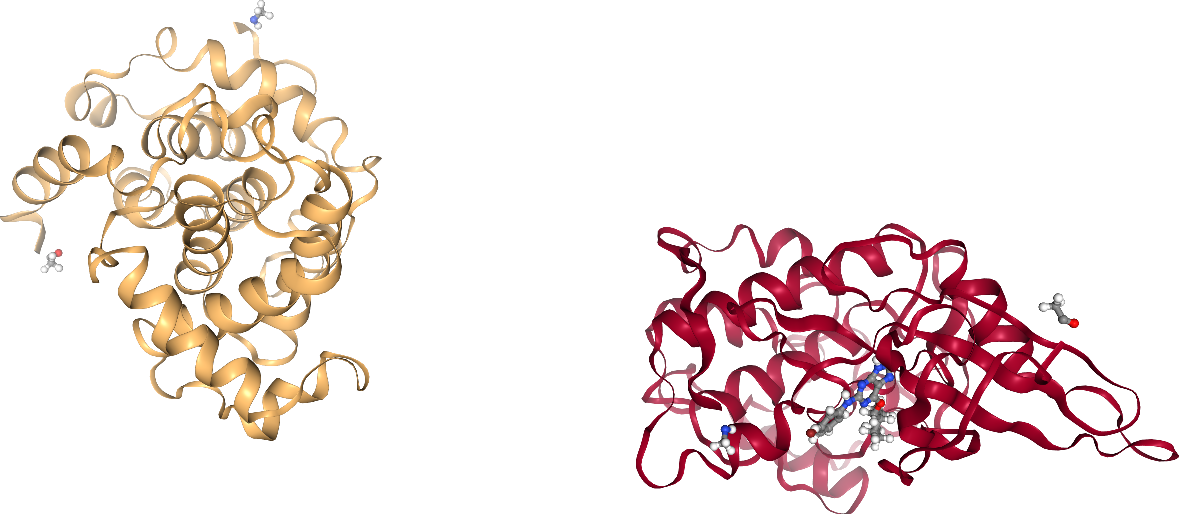

In [5]:
# Create the image
v.frame = 11
v.center("ligand", duration=0)
v.render_image(trim=True, factor=4)
v._display_image()

### Correcting for periodic boundary conditions and aligning frames

The split protein chains visible above are a visualization artifact caused by periodic boundary conditions. 
We can fix this using a helper method (`apply_complex_alignment_transformations`) that adds a set of [**MDAnalysis** Universe Transformations](https://docs.mdanalysis.org/stable/documentation_pages/trajectory_transformations.html) to the `Universe`, which are applied on-the-fly as frames are read:

- `unwrap`: Repairs the protein and ligand(s), ensuring each molecule is made whole across periodic box boundaries.
- `ClosestImageShift`: Shifts each protein chain and each ligand independently into the periodic image closest to the first protein chain. Ligands are shifted independently of one another, which is important in SepTop where two ligands can cross periodic boundaries at different times.
- `Aligner`: Aligns every frame to the first frame by minimizing the mass-weighted RMSD of the protein Cα atoms, removing overall translational and rotational drift.

For solvent leg simulations, use `apply_ligand_alignment_transformations` instead. Rather than `unwrap` and `ClosestImageShift`, it uses `NoJump`, which prevents the ligand from jumping between periodic images by tracking its centre-of-mass motion continuously across frames. It then aligns each frame by minimizing the ligand RMSD.

> **Note:** These transformations are appropriate for visualizing stable protein-ligand interactions and for RMSD-based analyses, but you should avoid alignment if you need to observe diffusive behaviour, such as tracking how a ligand or protein component moves through the simulation box over time.

In [6]:
protein_selection = "protein and name CA"
# The ligand residue name is usually `UNK` so that is how we select the ligand atoms here.
ligand_selection = "resname UNK"
# The topology contains no protein bonds, which are needed to make each protein chain whole
u_0.select_atoms("protein").guess_bonds()
prot = u_0.select_atoms(protein_selection)
ligand = u_0.select_atoms(ligand_selection)
# Add PBC-handling and alignment transformations to the Universe
apply_transformations.apply_complex_alignment_transformations(u_0, protein=prot, ligands=[ligand])

After applying the transformations, the protein chains should now appear whole:

In [ ]:
v = nv.show_mdanalysis(u_0)
v

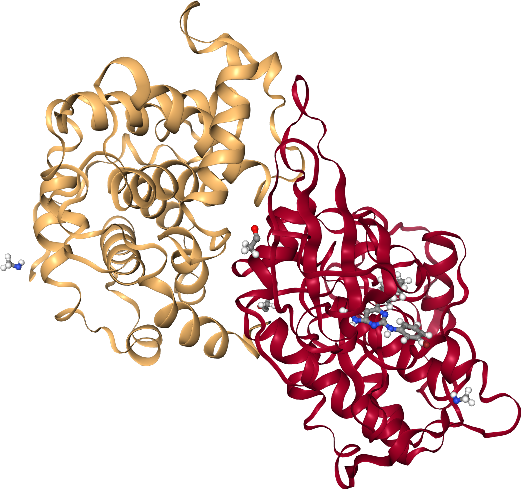

In [9]:
v.frame = 11
v.center()
v.render_image(trim=True, factor=4)
v._display_image()

<div class=\"alert alert-block alert-info\"> <b>Note:</b> The OpenFE relative binding free energy protocol does not save water positions by default, this can be changed via the <a href="https://docs.openfree.energy/en/latest/reference/api/openmm_protocol_settings.html#openfe.protocols.openmm_utils.omm_settings.MultiStateOutputSettings.output_indices"><code>output_indices</code></a> protocol setting. </div>

### Load and visualize `lambda=1`

At the final lambda state the hybrid ligand corresponds to ligand B. We use negative indexing in case the total number of lambda states is not known.

In [ ]:
u_1 = mda.Universe(rfe_complex_pdb, rfe_complex_nc, format=FEReader, index=-1, index_method='state')
# The topology contains no protein bonds, which are needed to make each protein chain whole
u_1.select_atoms("protein").guess_bonds()

prot = u_1.select_atoms(protein_selection)
ligand = u_1.select_atoms(ligand_selection)
apply_transformations.apply_complex_alignment_transformations(u_1, protein=prot, ligands=[ligand])

v = nv.show_mdanalysis(u_1)
v.center()
v

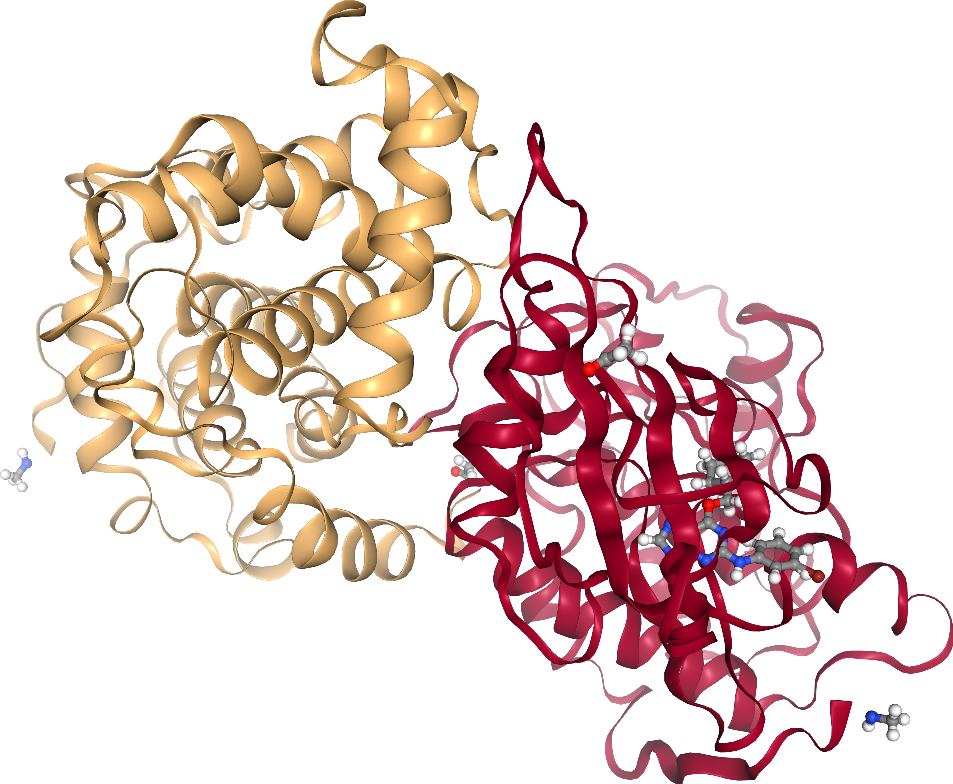

In [12]:
v.frame = 0
v.center("ligand", duration=0)
v.render_image(trim=True, factor=4)
v._display_image()

### Extracting end state atom positions

The hybrid topology encodes end-state identity in the temperature factors of the topology file, as described above. We use these to select the atoms relevant to each end state.

To extract each end state we combine the non-alchemical and core atoms,
which are shared between both states, with the atoms unique to that end state:
| End state | Non-alchemical (`0.0`) | Core (`0.5`) | Unique atoms |
|-----------|:---------------------:|:------------:|:------------:|
| Ligand A (`lambda=0`) | ✓ | ✓ | `0.25` |
| Ligand B (`lambda=-1`) | ✓ | ✓ | `0.75` |


In [ ]:
# get atoms for state A
state_a = u_0.atoms[u_0.atoms.tempfactors <= 0.5]
# get atoms for state B
state_b = sum([u_1.atoms[u_1.atoms.tempfactors == i] for i in (0.0, 0.5, 0.75)])

# Let's visualize state A
v = nv.show_mdanalysis(state_a)
v

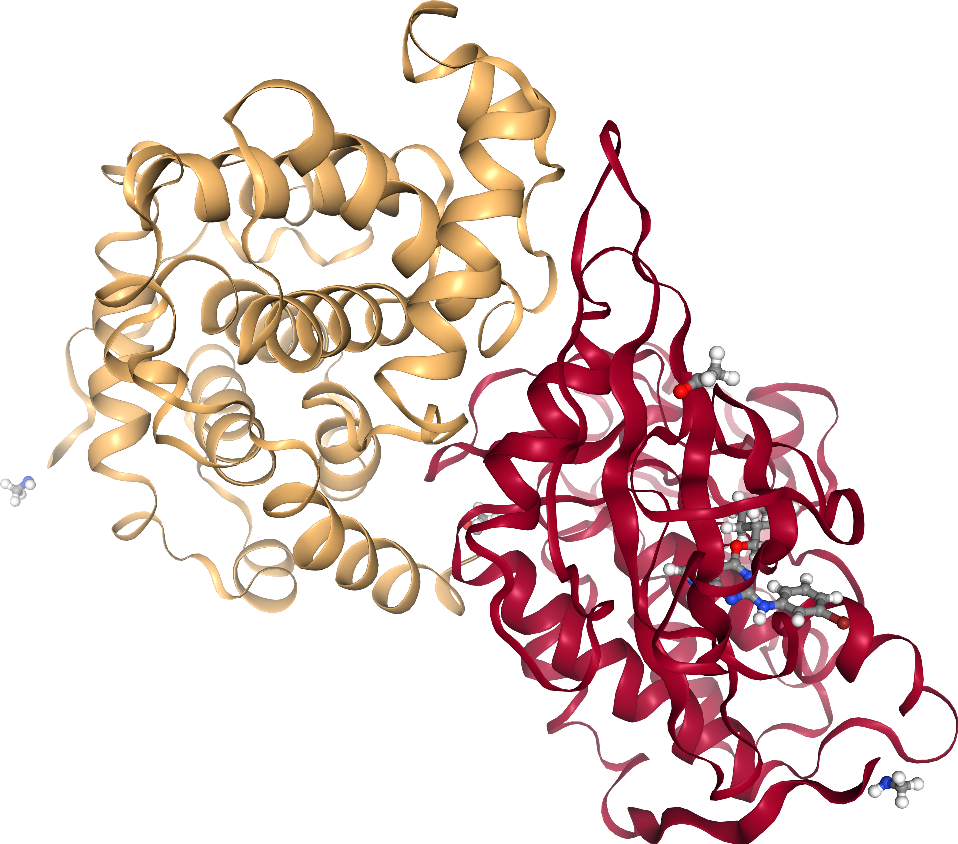

In [15]:
v.frame = 0
v.center("ligand", duration=0)
v.render_image(trim=True, factor=4)
v._display_image()

### Saving the trajectory to file

We can now use **MDAnalysis** to save the trajectory of the `state A` and `state B` atoms to a common file format, note that we will also need to write out a new topology file that can be used to load this trajectory:

In [16]:
# Endstate A
state_a.write("rfe_state_a_topology.pdb")
with mda.Writer("rfe_out_A.xtc", n_atoms=len(state_a.atoms)) as w:
    for ts in u_0.trajectory:
        w.write(state_a)

/Users/hannahbaumann/.local/share/mamba/envs/openfe_dev/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(


In [17]:
# Endstate B
state_b.write("rfe_state_b_topology.pdb")
with mda.Writer("rfe_out_B.xtc", n_atoms=len(state_b.atoms)) as w:
    for ts in u_1.trajectory:
        w.write(state_b)

## Separated Topologies Protocol (SepTop)

Unlike the relative hybrid topology protocol, SepTop represents both end-state ligands explicitly with unique atom positions throughout the entire simulation. Both ligands are always physically present in the simulation box, what changes across the lambda schedule is the alchemical coupling of each ligand to its environment. At `lambda=0` ligand A is fully coupled and ligand B is decoupled; at `lambda=1` the reverse is true.
This means trajectory loading and visualization looks similar to the hybrid topology case, except that there is no `tempfactor` encoding. Each ligand has its own full set of atom positions, so end-state extraction is straightforward index-based selection rather than `tempfactor` filtering.

### Setup

First we define the paths to the SepTop data and derive the ligand atom indices from the topology. In a real workflow these indices would be read from the protocol output JSON; here we derive them directly from residue ordering, which works because the two ligands share the residue name `UNK` but have different residue numbers.

In [18]:
septop_complex_pdb = septop_dir / "complex" / "alchemical_system.pdb"
septop_complex_nc = septop_dir / "complex" / "complex.nc"

u_tmp = mda.Universe(septop_complex_pdb)
unk_residues = u_tmp.select_atoms("resname UNK").residues
# The two ligands have distinct residue indices within the same residue name UNK,
# so we can select them by their order in the residue list
septop_lig_A_indices = unk_residues[0].atoms.indices.tolist()
septop_lig_B_indices = unk_residues[1].atoms.indices.tolist()

### Load and visualize `lambda=0` (SepTop)

At `lambda=0`, ligand A is fully coupled to its environment. We load this state and visualize both ligands together. Since both are physically present, they both appear in the view.

In [ ]:
u_septop_0 = mda.Universe(septop_complex_pdb, septop_complex_nc, format=FEReader, index=0, index_method='state')
v = nv.show_mdanalysis(u_septop_0)
v.center("resname UNK")
v

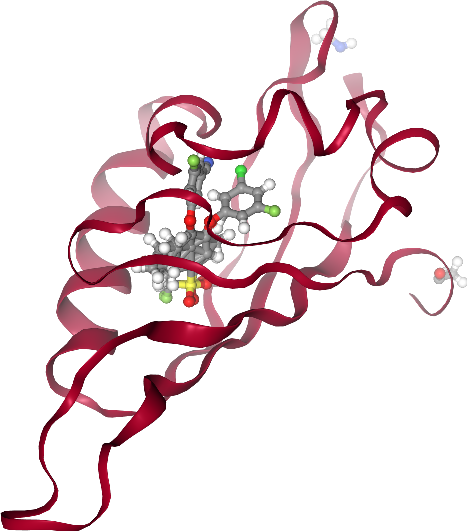

In [21]:
v.frame = 0
v.center("resname UNK", duration=0)
v.render_image(trim=True, factor=4)
v._display_image()

### Correcting for periodic boundary conditions and aligning frames (SepTop)

As with the hybrid topology case, PBC artifacts may cause the protein chains to appear split or the ligands to appear displaced from the binding pocket. 
We fix this by calling `apply_complex_alignment_transformations`, which adds a set of [**MDAnalysis** Universe Transformations](https://docs.mdanalysis.org/stable/documentation_pages/trajectory_transformations.html) to the `Universe` that are applied on-the-fly as frames are read. Both ligands are passed as separate `AtomGroups` so that each is imaged independently relative to the protein. 
Passing them as a combined group can introduce imaging artifacts when one ligand crosses a periodic boundary independently of the other.

In [ ]:
# The topology contains no protein bonds, which are needed to make each protein chain whole
u_septop_0.select_atoms("protein").guess_bonds()

prot = u_septop_0.select_atoms(protein_selection)
lig_A_0 = u_septop_0.atoms[septop_lig_A_indices]
lig_B_0 = u_septop_0.atoms[septop_lig_B_indices]

# Add PBC-handling and alignment transformations to the Universe,
# imaging each ligand independently relative to the protein
apply_transformations.apply_complex_alignment_transformations(
    u_septop_0, protein=prot, ligands=[lig_A_0, lig_B_0]
)

v = nv.show_mdanalysis(u_septop_0)
v.center("resname UNK")
v

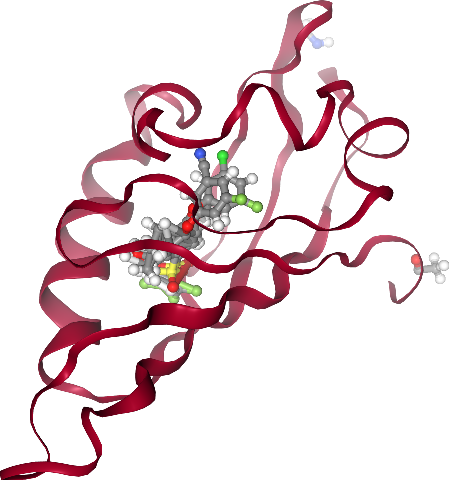

In [24]:
v.frame = 5
v.center("resname UNK", duration=0)
v.render_image(trim=True, factor=4)
v._display_image()

### Load and visualize `lambda=1` (SepTop)

At the final lambda state, ligand B is fully coupled. We use negative indexing as before.

In [ ]:
u_septop_1 = mda.Universe(septop_complex_pdb, septop_complex_nc,
                           format=FEReader, index=-1, index_method='state')
# The topology contains no protein bonds, which are needed to make each protein chain whole
u_septop_1.select_atoms("protein").guess_bonds()

prot = u_septop_1.select_atoms(protein_selection)
lig_A_1 = u_septop_1.atoms[septop_lig_A_indices]
lig_B_1 = u_septop_1.atoms[septop_lig_B_indices]

apply_transformations.apply_complex_alignment_transformations(
    u_septop_1, protein=prot, ligands=[lig_A_1, lig_B_1]
)

v = nv.show_mdanalysis(u_septop_1)
v.center("resname UNK")
v

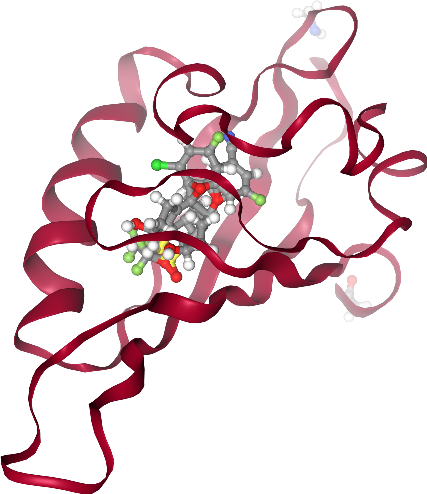

In [27]:
v.frame = 0
v.center("resname UNK", duration=0)
v.render_image(trim=True, factor=4)
v._display_image()

### Extracting end-state atom positions

Because SepTop preserves full atom identity for each ligand, there is no `tempfactor` encoding to interpret. 
We select each ligand directly by its atom indices.

In [ ]:
# State A: protein + ligand A
state_a = u_septop_0.select_atoms("protein") + lig_A_0

v = nv.show_mdanalysis(state_a)
v.center("resname UNK")
v

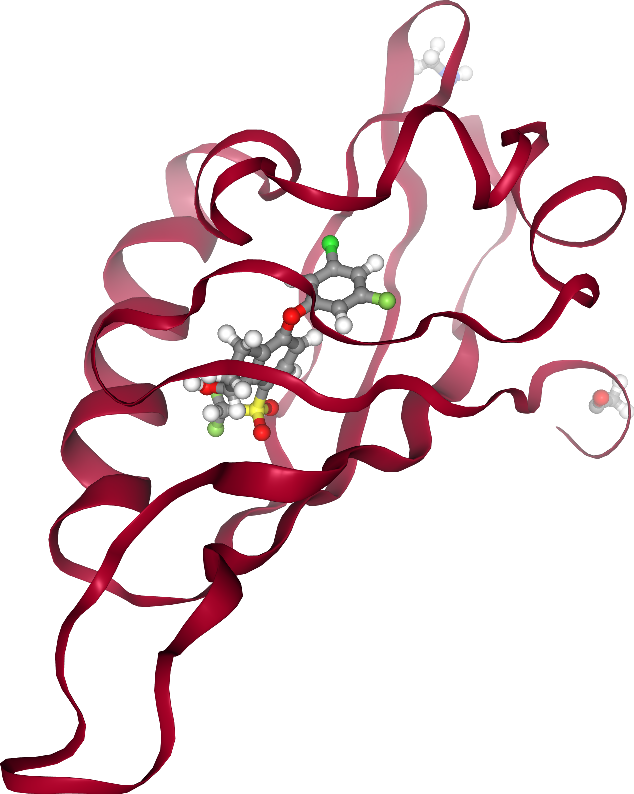

In [30]:
v.frame = 0
v.center("resname UNK", duration=0)
v.render_image(trim=True, factor=4)
v._display_image()

### Saving the trajectories to file

We write a topology and trajectory for each end-state ligand separately.

In [31]:
# Ligand A
state_a.write("septop_state_a_topology.pdb")
with mda.Writer("septop_out_A.xtc", n_atoms=len(state_a.atoms)) as w:
    for ts in u_septop_0.trajectory:
        w.write(state_a)

/Users/hannahbaumann/.local/share/mamba/envs/openfe_dev/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(


In [32]:
# State B: protein + ligand B
state_b = u_septop_1.select_atoms("protein") + lig_B_1

state_b.write("septop_state_b_topology.pdb")
with mda.Writer("septop_out_B.xtc", n_atoms=len(state_b.atoms)) as w:
    for ts in u_septop_1.trajectory:
        w.write(state_b)